In [106]:
# Import necessary libraries for data manipulation, financial analysis, HMM, and plotting
import warnings
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from scipy.optimize import minimize
from pathlib import Path
warnings.filterwarnings("ignore")

In [107]:
# Define tickers, download historical data, and calculate various financial features (returns, volatilities, momentum, correlation, VIX level) for HMM.
TICKERS = ["SPY", "TLT", "GLD", "^VIX"]

prices = yf.download(
    TICKERS,
    start="2005-01-01",
    end="2026-06-30",
    auto_adjust=True,
    progress=False)["Close"]

prices = prices.dropna()
log_returns = np.log(prices / prices.shift(1))
log_returns = log_returns.dropna()

rolling_vol = log_returns["SPY"].rolling(window=63).std() * np.sqrt(252)

rolling_mean = log_returns["SPY"].rolling(window=252).mean()

rolling_var = log_returns["SPY"].rolling(window=252).var()

features = log_returns.copy()

features.columns = [
    "GLD_Return",
    "SPY_Return",
    "TLT_Return",
    "VIX_Return"]

# 20-day rolling volatility
rolling_vol_20 = features.rolling(window=20).std()

rolling_vol_20.columns = ["GLD_Vol20","SPY_Vol20","TLT_Vol20","VIX_Vol20"]

features = pd.concat([features, rolling_vol_20],axis=1)

features = features.dropna()

rolling_vol_63 = (features[["GLD_Return", "SPY_Return", "TLT_Return", "VIX_Return"]].rolling(window=63).std())
rolling_vol_63.columns = ["GLD_Vol63","SPY_Vol63","TLT_Vol63","VIX_Vol63",]

features = pd.concat([features, rolling_vol_63],axis=1)

features = features.dropna()

# 20-Day Momentum
momentum_20 = (prices.pct_change(periods=20))
momentum_20.columns = ["GLD_Mom20","SPY_Mom20","TLT_Mom20","VIX_Mom20"] # Renaming for consistency

momentum_63 = (prices.pct_change(periods=63))
momentum_63.columns = [
    "GLD_Mom63",
    "SPY_Mom63",
    "TLT_Mom63",
    "VIX_Mom63"]

momentum_20 = momentum_20.loc[features.index]
momentum_63 = momentum_63.loc[features.index]

features = pd.concat([features,momentum_20,momentum_63],axis=1)
features = features.dropna()

rolling_corr_spy_tlt = (
    features["SPY_Return"]
    .rolling(window=20)
    .corr(features["TLT_Return"]))

rolling_corr_spy_tlt.name = "SPY_TLT_Corr20"
features = pd.concat([features, rolling_corr_spy_tlt],axis=1)
features = features.dropna()
vix_level = prices["^VIX"].loc[features.index]
features["VIX_Level"] = vix_level

In [108]:
# Define the list of observation features for the HMM and create a copy 'X' from the features DataFrame.
observation_features = [
    "SPY_Return",
    "TLT_Return",

    "SPY_Vol20",
    "SPY_Vol63",

    "TLT_Vol20",
    "TLT_Vol63",

    "SPY_Mom20",
    "SPY_Mom63",

    "TLT_Mom20",
    "TLT_Mom63",

    "SPY_TLT_Corr20",

    "VIX_Level"]

X = features[observation_features].copy()

In [109]:
# Initialize and apply StandardScaler to normalize the observation features, then convert back to DataFrame.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    index=X.index,
    columns=observation_features)

In [110]:
# Train GaussianHMM models for a range of hidden states, evaluating each with Log-Likelihood, AIC, and BIC.
candidate_states = [2,3,4,5]
model_results = []
trained_models = {}
for n_states in candidate_states:

    model = GaussianHMM(n_components=n_states,covariance_type="full",n_iter=1000,random_state=12)

    model.fit(X_scaled)

    log_likelihood = model.score(X_scaled)

    n_features = X_scaled.shape[1]
    # Number of free parameters: transition matrix, means, and covariance matrices
    n_parameters = ((n_states - 1) + n_states * (n_states - 1) + n_states * n_features
        + n_states * n_features * (n_features + 1) / 2)

    n_samples = X_scaled.shape[0]
    aic = 2 * n_parameters - 2 * log_likelihood
    bic = (np.log(n_samples) * n_parameters - 2 * log_likelihood)

    model_results.append({
        "States": n_states,
        "LogLikelihood": log_likelihood,
        "Parameters": int(n_parameters),
        "AIC": aic,
        "BIC": bic,
        "Converged": model.monitor_.converged})

    trained_models[n_states] = model

In [111]:
# Select the best HMM model (5 states) and predict the hidden states (regimes), then count their occurrences.
best_model = trained_models[5]
hidden_states = best_model.predict(X_scaled)
state_counts = (pd.Series(hidden_states).value_counts().sort_index())

In [112]:
# Define portfolio assets, add predicted regimes to features, and group asset returns by regime.
portfolio_assets = ["SPY_Return", "TLT_Return", "GLD_Return"]

features["Regime"] = hidden_states

regime_returns = {}
for regime in sorted(features["Regime"].unique()):

    regime_data = features.loc[features["Regime"] == regime, portfolio_assets]

    regime_returns[regime] = regime_data.copy()

In [113]:
# Calculate mean returns and covariance matrices for each asset within each identified market regime.
regime_mean_returns = {}

for regime, data in regime_returns.items():

    regime_mean_returns[regime] = data.mean()

# Calculate the covariance matrix for asset returns within each identified market regime
regime_covariance = {}

for regime, data in regime_returns.items():

    regime_covariance[regime] = data.cov()

In [114]:
# Define a function to calculate the negative Sharpe ratio, used as the objective for portfolio optimization.
def negative_sharpe(weights, mean_returns, cov_matrix, risk_free_rate=0):

    # Portfolio expected return
    portfolio_return = np.dot(weights, mean_returns)

    # Portfolio volatility
    portfolio_volatility = np.sqrt(
        np.dot(weights.T,
               np.dot(cov_matrix, weights)))

    # Avoid division by zero
    if portfolio_volatility == 0:
        return np.inf

    sharpe_ratio = (portfolio_return - risk_free_rate) / portfolio_volatility
    return -sharpe_ratio

In [115]:
# Determine the number of assets and initialize equal weights as a starting point for optimization.
n_assets = len(portfolio_assets)
initial_weights = np.ones(n_assets) / n_assets

In [116]:
# Define constraints (sum of weights = 1) and bounds (weights between 0 and 1) for portfolio optimization.
constraints = ({"type": "eq", "fun": lambda w: np.sum(w) - 1},)

# Define bounds for the optimization: each asset's weight must be between 0 and 1 (inclusive)
bounds = tuple((0, 1) for _ in range(n_assets))

In [117]:
# Optimize portfolio for each regime by minimizing the negative Sharpe ratio using regime-specific returns and covariance.
optimized_portfolios = {}

for regime in sorted(regime_mean_returns.keys()):
    mean_returns_for_regime = regime_mean_returns[regime]
    cov_matrix_for_regime = regime_covariance[regime]

    result = minimize(
        fun=negative_sharpe,
        x0=initial_weights,
        args=(mean_returns_for_regime, cov_matrix_for_regime),
        method="SLSQP",
        bounds=bounds,
        constraints=constraints)

    optimized_portfolios[regime] = result

In [118]:
# Extract optimal weights from the last optimization result and display them.
optimal_weights = result.x
optimal_weights

array([0.83922494, 0.        , 0.16077506])

In [119]:
# Calculate and display the portfolio's expected return, volatility, and Sharpe ratio for the selected regime (Regime 4).
selected_regime = 4 # Since optimal_weights were derived from the last regime (Regime 4)

portfolio_return = np.dot(
    optimal_weights,
    regime_mean_returns[selected_regime])

portfolio_volatility = np.sqrt(
    np.dot(
        optimal_weights.T,
        np.dot(regime_covariance[selected_regime], optimal_weights)))

portfolio_sharpe = (portfolio_return/portfolio_volatility)

In [120]:
# Encapsulate the portfolio optimization logic into a reusable function for finding optimal asset weights.
def optimize_portfolio(mean_returns,
                       cov_matrix,
                       risk_free_rate=0):

    n_assets = len(mean_returns)

    initial_weights = np.ones(n_assets) / n_assets

    constraints = ({"type": "eq", "fun": lambda w: np.sum(w) - 1},)

    bounds = tuple((0, 1) for _ in range(n_assets))

    result = minimize(
        negative_sharpe,
        initial_weights,
        args=(mean_returns,
              cov_matrix,
              risk_free_rate),
        method="SLSQP",
        bounds=bounds,
        constraints=constraints)

    return result

In [121]:
# Re-run portfolio optimization for each regime using the `optimize_portfolio` function.
optimized_portfolios = {}

for regime in regime_mean_returns.keys():

    result = optimize_portfolio(
        regime_mean_returns[regime],
        regime_covariance[regime]
    )

    optimized_portfolios[regime] = result

In [122]:
# Copy asset returns to `portfolio_returns` DataFrame.
portfolio_returns = features[["SPY_Return","TLT_Return","GLD_Return"]].copy()

In [123]:
# Add the predicted regimes to the `portfolio_returns` DataFrame and shift them by one day to avoid look-ahead bias.
portfolio_returns["Regime"] = hidden_states

portfolio_returns["Regime"] = (
    portfolio_returns["Regime"]
    .shift(1)
)

In [124]:
# Remove any rows with missing data (NaN) after shifting the regimes.
portfolio_returns = portfolio_returns.dropna()

In [125]:
# Convert the 'Regime' column to integer type.
portfolio_returns["Regime"] = (
    portfolio_returns["Regime"]
    .astype(int)
)

In [126]:
# Display the first few rows of the portfolio returns DataFrame with regimes.
portfolio_returns.head()

,SPY_Return,TLT_Return,GLD_Return,Regime
Date,,,,
2005-05-31,-0.006424,0.012285,-0.005507,4
2005-06-01,0.008501,0.012170,-0.002885,4
2005-06-02,0.002156,0.002399,0.013632,4
2005-06-03,-0.005064,-0.008260,0.001661,4
2005-06-06,-0.000916,0.005236,0.007324,4


In [127]:
# Print the number of rows in `portfolio_returns` and `hidden_states`.
print(len(portfolio_returns))
print(len(hidden_states))

5303
5304


In [128]:
# Check for any remaining null values in the portfolio returns DataFrame.
portfolio_returns.isna().sum()

,0
SPY_Return,0
TLT_Return,0
GLD_Return,0
Regime,0


In [129]:
# Count the occurrences of each regime in the portfolio returns.
portfolio_returns["Regime"].value_counts().sort_index()

,count
Regime,
0,1317
1,678
2,1208
3,180
4,1920


In [130]:
# Ensure the 'Regime' column is of integer type.
portfolio_returns["Regime"] = (
    portfolio_returns["Regime"]
    .astype(int))

In [131]:
# Extract optimal weights for each regime from optimized portfolios and store them in a DataFrame.
weights = []

for regime, result in optimized_portfolios.items():

    weights.append(
        pd.Series(
            result.x,
            index=portfolio_assets, # Using portfolio_assets for index names
            name=f"Regime {regime}"
        )
    )

weights_df = pd.DataFrame(weights)

In [132]:
# Simulate portfolio performance, applying regime-specific weights and accounting for transaction costs.
strategy_returns = []
portfolio_values = [1.0] # Starting with an initial portfolio value of 1
daily_weights = []
daily_turnover = [] # Initialize daily_turnover list
previous_weights = None
transaction_cost = 0.001 # 10 basis points (0.1%)

# Loop through each day's data to simulate portfolio performance
for date, row in portfolio_returns.iterrows():
    regime = int(row["Regime"])

    weights = weights_df.loc[
        f"Regime {regime}"
    ].values

    # Calculate turnover
    if previous_weights is None:
        turnover = 0
    else:
        turnover = np.sum(np.abs(weights - previous_weights))

    daily_turnover.append(turnover) # Append turnover for each day

    # Calculate cost
    cost = turnover * transaction_cost

    daily_asset_returns = row[portfolio_assets]
    daily_portfolio_return = np.dot(weights, daily_asset_returns)

    # Apply cost to daily return
    daily_return_after_cost = daily_portfolio_return - cost

    strategy_returns.append(daily_return_after_cost)

    latest_portfolio_value = portfolio_values[-1] * (1 + daily_return_after_cost)
    portfolio_values.append(latest_portfolio_value)

    daily_weights.append(weights)
    previous_weights = weights # Update previous_weights for the next iteration

strategy_returns = pd.Series(
    strategy_returns,
    index=portfolio_returns.index,
    name="Strategy_Return")

In [133]:
# Calculate cumulative strategy returns and cumulative asset returns for comparison.
cumulative_strategy_returns = (1 + strategy_returns).cumprod()
cumulative_strategy_returns.name = "Cumulative Strategy Returns"

# Also calculate cumulative returns for individual assets for comparison
cumulative_asset_returns = (1 + portfolio_returns[portfolio_assets]).cumprod()
cumulative_asset_returns.name = "Cumulative Asset Returns"


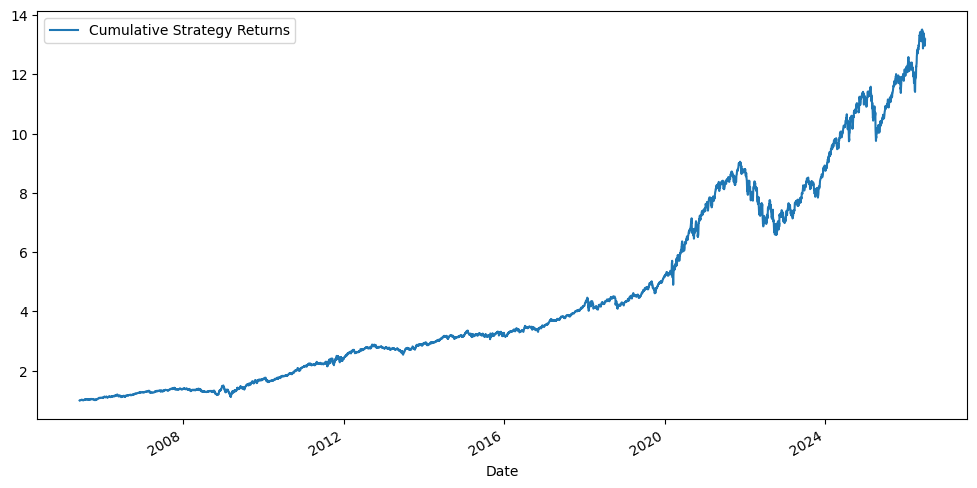

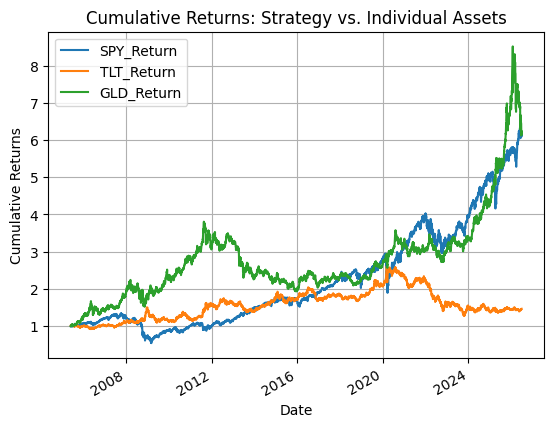

In [134]:
# Plot the cumulative returns of the strategy against individual assets for visual comparison.
plt.figure(figsize=(12, 6))
cumulative_strategy_returns.plot(legend=True)
cumulative_asset_returns.plot(legend=True)
plt.title('Cumulative Returns: Strategy vs. Individual Assets')
plt.xlabel('Date')
plt.ylabel('Cumulative Returns')
plt.grid(True)
plt.show()

In [135]:
# Calculate and print the Annualized Return, Annualized Volatility, and Sharpe Ratio of the strategy.

# Assuming 252 trading days in a year
annualization_factor = 252

# Annualized Return
annualized_return = (cumulative_strategy_returns.iloc[-1]**(annualization_factor/len(cumulative_strategy_returns))) - 1

# Annualized Volatility
annualized_volatility = strategy_returns.std() * np.sqrt(annualization_factor)

# Sharpe Ratio
# Assuming risk-free rate is 0 for simplicity, adjust if a specific risk-free rate is available
risk_free_rate = 0
sharpe_ratio = (annualized_return - risk_free_rate) / annualized_volatility

print(f"Annualized Return: {annualized_return:.2%}")
print(f"Annualized Volatility: {annualized_volatility:.2%}")
print(f"Sharpe Ratio: {sharpe_ratio:.2f}")

Annualized Return: 13.03%
Annualized Volatility: 13.09%
Sharpe Ratio: 1.00


In [136]:
# Convert the list of portfolio values to a pandas Series, excluding the initial value.
portfolio_values = pd.Series(
    portfolio_values[1:],
    index=portfolio_returns.index,
    name="Portfolio_Value")

In [137]:
# Display the first few strategy returns.
strategy_returns.head()

,Strategy_Return
Date,
2005-05-31,-0.006277
2005-06-01,0.006670
2005-06-02,0.004001
2005-06-03,-0.003983
2005-06-06,0.000409


In [138]:
# Display the first few portfolio values.
portfolio_values.head()

,Portfolio_Value
Date,
2005-05-31,0.993723
2005-06-01,1.000351
2005-06-02,1.004354
2005-06-03,1.000353
2005-06-06,1.000762


In [139]:
# Initialize `previous_weights` to None and define the transaction cost.
previous_weights = None

transaction_cost = 0.001   # 10 basis points (0.10%)

In [140]:
# Calculate turnover based on weight changes from the previous period, or set to 0 if no previous weights exist.
if previous_weights is None:

    turnover = 0

else:

    turnover = np.sum(np.abs(weights - previous_weights))

In [141]:
# Calculate the transaction cost based on turnover and the defined transaction_cost rate.
cost = turnover * transaction_cost

In [142]:
# Convert the list of daily turnover values into a pandas Series.
daily_turnover = pd.Series(
    daily_turnover,
    index=portfolio_returns.index,
    name="Turnover")

In [143]:
# Display descriptive statistics for the daily portfolio turnover.
daily_turnover.describe()

,Turnover
count,5303.000000
mean,0.020944
std,0.156719
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,2.000000


In [144]:
# Calculate and print the number of rebalance days and their percentage of total trading days.
rebalance_days = (daily_turnover > 0).sum()

rebalance_percentage = (
    rebalance_days
    /
    len(daily_turnover)
    *100
)

print(f"Rebalance Days : {rebalance_days}")

print(f"Percentage : {rebalance_percentage:.2f}%")

Rebalance Days : 123
Percentage : 2.32%


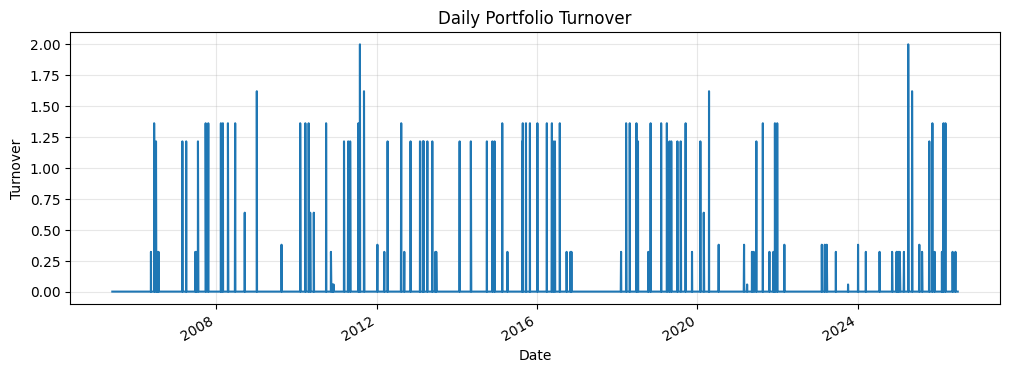

In [145]:
# Plot the daily portfolio turnover over time.
plt.figure(figsize=(12,4))
daily_turnover.plot()
plt.title("Daily Portfolio Turnover")
plt.ylabel("Turnover")
plt.grid(alpha=0.3)
plt.show()

In [146]:
# Display the head and tail of the portfolio values to show the overall growth trajectory.
print(portfolio_values.head())
print(portfolio_values.tail())

Date
2005-05-31    0.993723
2005-06-01    1.000351
2005-06-02    1.004354
2005-06-03    1.000353
2005-06-06    1.000762
Name: Portfolio_Value, dtype: float64
Date
2026-06-23    13.042210
2026-06-24    13.036163
2026-06-25    13.054995
2026-06-26    12.960246
2026-06-29    13.172025
Name: Portfolio_Value, dtype: float64


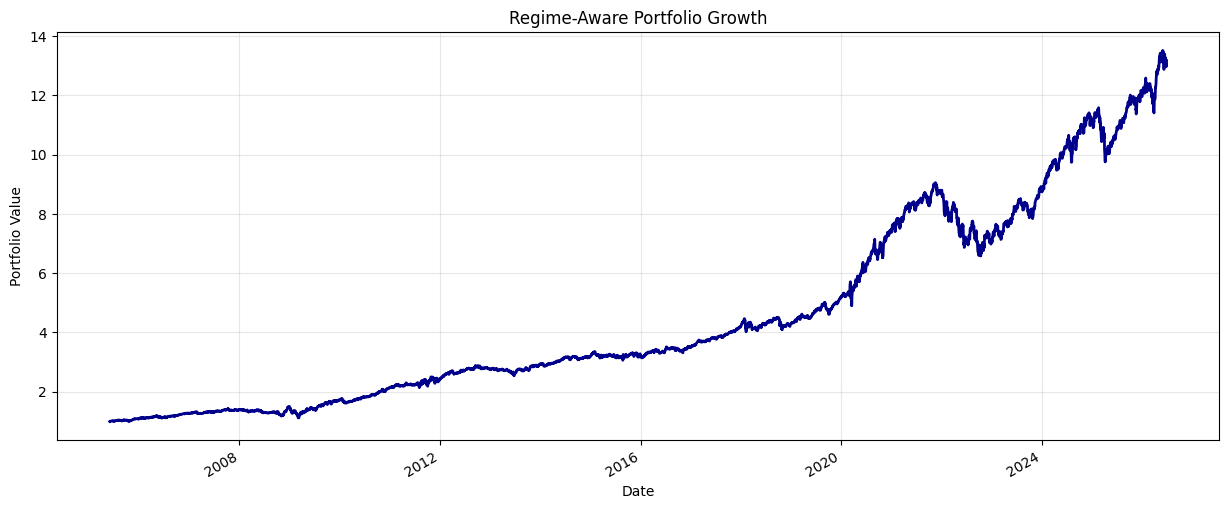

In [147]:
# Plot the portfolio growth curve for the regime-aware strategy.
plt.figure(figsize=(15,6))
portfolio_values.plot(color="darkblue", linewidth=2)
plt.title("Regime-Aware Portfolio Growth")
plt.xlabel("Date")
plt.ylabel("Portfolio Value")
plt.grid(alpha=0.3)
plt.show()

In [148]:
# Calculate and print the total return of the strategy.
total_return = portfolio_values.iloc[-1] - 1
print(f"Total Return: {total_return:.2%}")

Total Return: 1217.20%


In [149]:
# Calculate and print the Compound Annual Growth Rate (CAGR) of the strategy.
years = (portfolio_values.index[-1] - portfolio_values.index[0]).days / 365.25
cagr = (portfolio_values.iloc[-1]**(1 / years)) - 1
print(f"CAGR: {cagr:.2%}")

CAGR: 13.01%


In [150]:
# Calculate SPY (S&P 500) returns and its cumulative equity curve for benchmark comparison.
spy_returns = portfolio_returns["SPY_Return"]
spy_equity = (1 + spy_returns).cumprod()

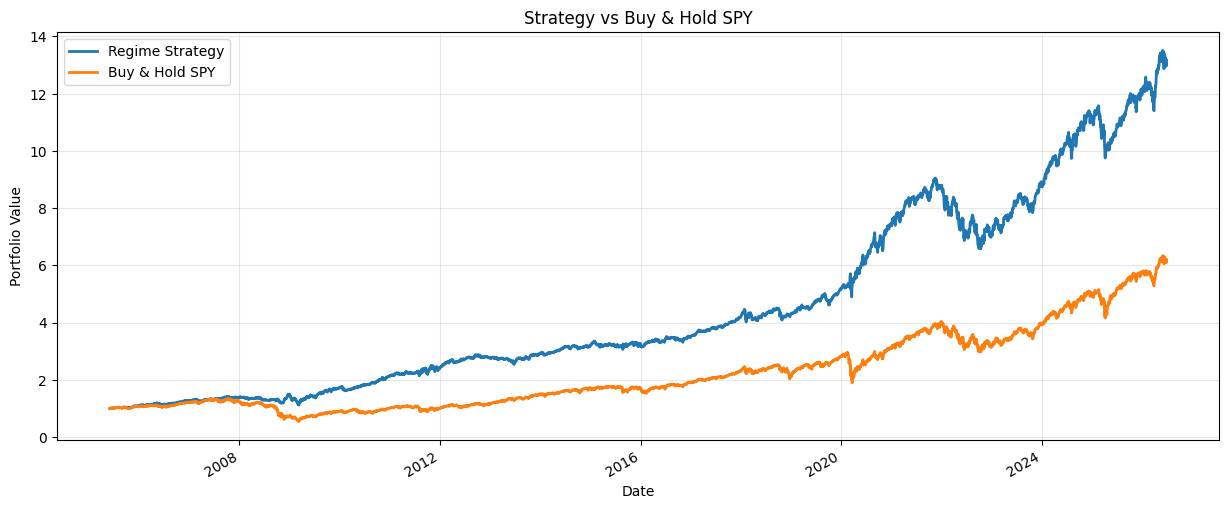

In [151]:
# Plot the strategy's portfolio value against a simple Buy & Hold SPY benchmark.
plt.figure(figsize=(15,6))
portfolio_values.plot(label="Regime Strategy", linewidth=2)
spy_equity.plot(label="Buy & Hold SPY", linewidth=2)
plt.title("Strategy vs Buy & Hold SPY")
plt.ylabel("Portfolio Value")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [152]:
# Calculate and print the annual return of the strategy.
annual_return = strategy_returns.mean() * 252
print(f"Annual Return: {annual_return:.2%}")

Annual Return: 13.11%


In [153]:
# Calculate and print the annual volatility of the strategy.
annual_volatility = strategy_returns.std() * np.sqrt(252)
print(f"Annual Volatility: {annual_volatility:.2%}")

Annual Volatility: 13.09%


In [154]:
# Calculate and print the Sharpe Ratio for the strategy.
sharpe = annual_return / annual_volatility
print(f"Sharpe Ratio: {sharpe:.2f}")

Sharpe Ratio: 1.00


In [155]:
# Calculate the rolling maximum portfolio value for drawdown calculation.
rolling_max = portfolio_values.cummax()

In [156]:
# Calculate the drawdown (percentage drop from peak equity).
drawdown = (portfolio_values - rolling_max) / rolling_max

In [157]:
# Calculate and print the maximum drawdown of the strategy.
max_drawdown = drawdown.min()
print(f"Maximum Drawdown: {max_drawdown:.2%}")

Maximum Drawdown: -27.30%


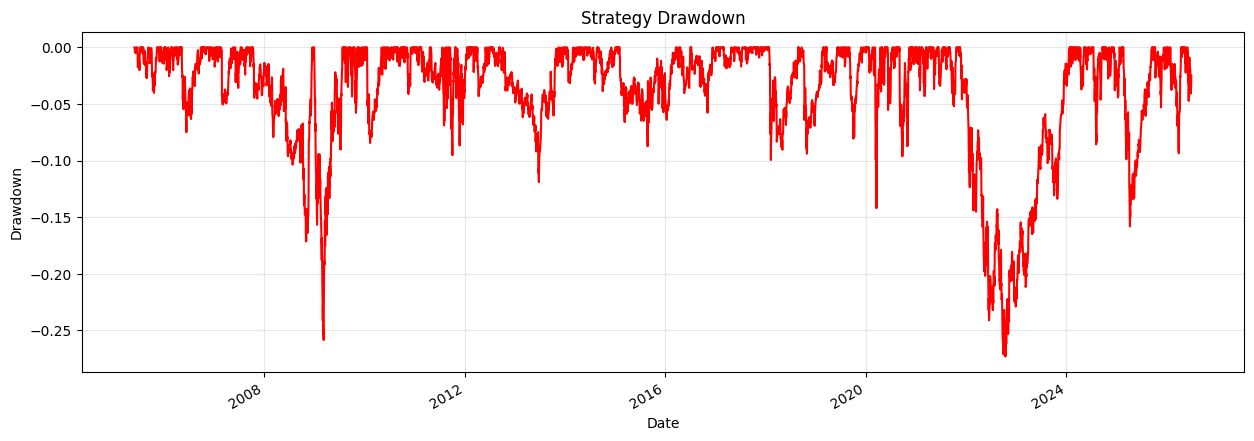

In [158]:
# Plot the strategy's drawdown over time.
plt.figure(figsize=(15,5))
drawdown.plot(color="red")
plt.title("Strategy Drawdown")
plt.ylabel("Drawdown")
plt.grid(alpha=0.3)
plt.show()

In [159]:
# Calculate and print the Calmar Ratio for the strategy (CAGR / absolute Max Drawdown).
calmar = cagr / abs(max_drawdown)
print(f"Calmar Ratio: {calmar:.2f}")

Calmar Ratio: 0.48


In [160]:
# Calculate downside returns, downside volatility, and the Sortino Ratio for the strategy.
downside_returns = strategy_returns[strategy_returns < 0]
downside_vol = downside_returns.std() * np.sqrt(252)
sortino = annual_return / downside_vol
print(f"Sortino Ratio: {sortino:.2f}")

Sortino Ratio: 1.27


In [161]:
# Create and display a DataFrame summarizing key performance metrics for the strategy.
performance_summary = pd.DataFrame({

    "Metric": [

        "Total Return",

        "CAGR",

        "Annual Return",

        "Annual Volatility",

        "Sharpe Ratio",

        "Sortino Ratio",

        "Maximum Drawdown",

        "Calmar Ratio"

    ],

    "Value": [

        f"{total_return:.2%}",

        f"{cagr:.2%}",

        f"{annual_return:.2%}",

        f"{annual_volatility:.2%}",

        f"{sharpe:.2f}",

        f"{sortino:.2f}",

        f"{max_drawdown:.2%}",

        f"{calmar:.2f}"]})

performance_summary

,Metric,Value
0,Total Return,1217.20%
1,CAGR,13.01%
2,Annual Return,13.11%
3,Annual Volatility,13.09%
4,Sharpe Ratio,1.00
5,Sortino Ratio,1.27
6,Maximum Drawdown,-27.30%
7,Calmar Ratio,0.48


In [162]:
# Define equal weights for assets (SPY, TLT, GLD) and calculate the returns of the equally weighted portfolio.
equal_weights = np.array([1/3, 1/3, 1/3])

equal_returns = (portfolio_returns[portfolio_assets]@ equal_weights)

In [163]:
# Calculate the cumulative equity curve for the equally weighted portfolio.
equal_equity = (1 + equal_returns).cumprod()

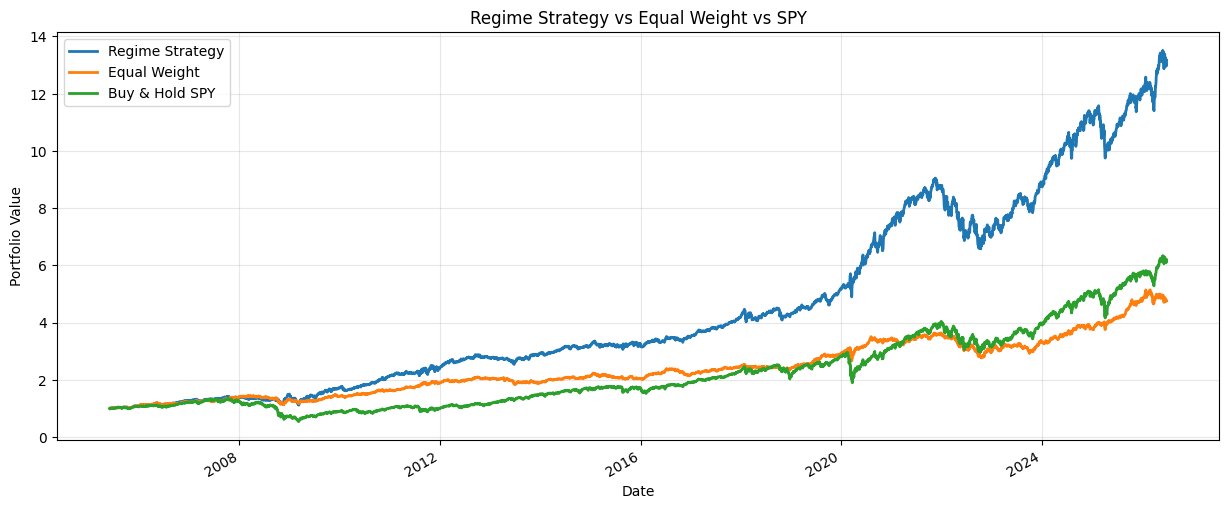

In [164]:
# Plot the equity curves of the regime strategy, equally weighted portfolio, and Buy & Hold SPY for comparison.
plt.figure(figsize=(15,6))
portfolio_values.plot(label="Regime Strategy", linewidth=2)
equal_equity.plot(label="Equal Weight", linewidth=2)
spy_equity.plot(label="Buy & Hold SPY", linewidth=2)
plt.title("Regime Strategy vs Equal Weight vs SPY")
plt.ylabel("Portfolio Value")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [165]:
# Define weights for a traditional 60/40 portfolio (60% SPY, 40% TLT) and calculate its returns.
weights_6040 = np.array([0.60, 0.40, 0.00])

returns_6040 = (portfolio_returns[portfolio_assets]@ weights_6040)

In [166]:
# Calculate the cumulative equity curve for the 60/40 portfolio.
equity_6040 = (1 + returns_6040).cumprod()

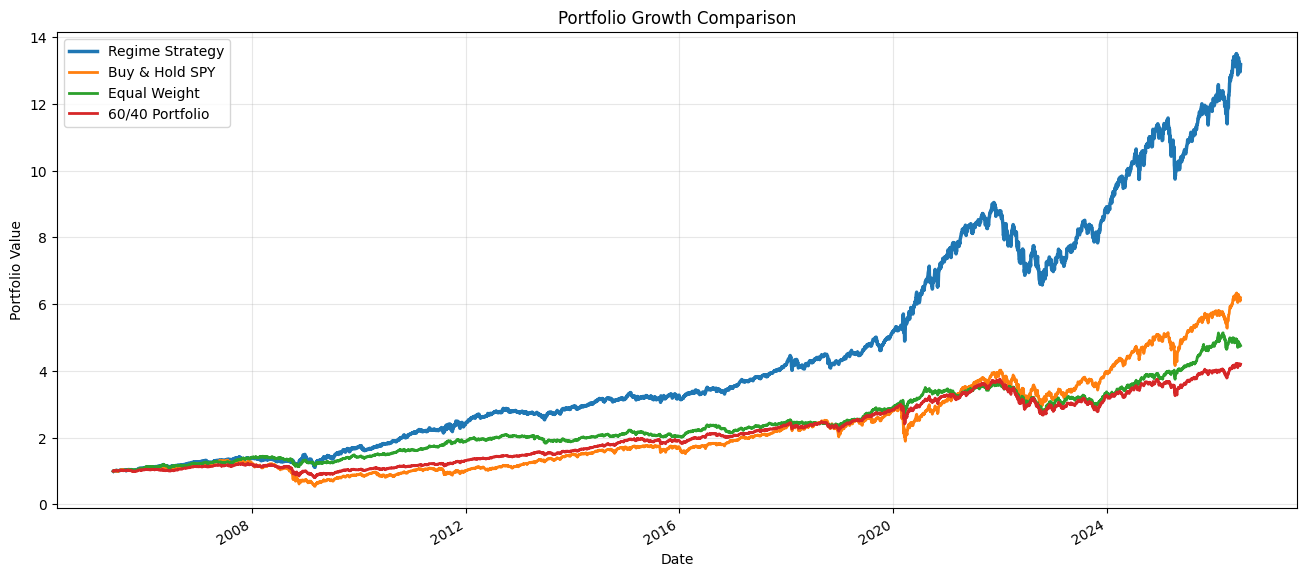

In [167]:
# Plot a comprehensive comparison of portfolio growth for all strategies and benchmarks.
plt.figure(figsize=(16,7))
portfolio_values.plot(linewidth=2.5,label="Regime Strategy")
spy_equity.plot(linewidth=2, label="Buy & Hold SPY")
equal_equity.plot(linewidth=2, label="Equal Weight")
equity_6040.plot(linewidth=2, label="60/40 Portfolio")
plt.title("Portfolio Growth Comparison")
plt.xlabel("Date")
plt.ylabel("Portfolio Value")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [168]:
def evaluate_strategy(equity_curve, daily_returns):
    # Calculate number of years for annualized metrics
    years = (equity_curve.index[-1] - equity_curve.index[0]).days / 365.25

    # Total Return
    total_return = equity_curve.iloc[-1] - 1

    # Compound Annual Growth Rate (CAGR)
    cagr = (equity_curve.iloc[-1]** (1 / years)) - 1

    # Annualized Return
    annual_return = daily_returns.mean() * 252

    # Annualized Volatility
    annual_vol = daily_returns.std() * np.sqrt(252)

    # Sharpe Ratio (assuming 0 risk-free rate)
    sharpe = annual_return / annual_vol

    # Downside returns for Sortino Ratio calculation
    downside = daily_returns[daily_returns < 0]

    # Sortino Ratio
    sortino = annual_return / (downside.std() * np.sqrt(252))

    # Calculate Max Drawdown
    rolling_max = equity_curve.cummax()
    drawdown = (equity_curve - rolling_max) / rolling_max
    max_dd = drawdown.min()

    # Calmar Ratio
    calmar = cagr / abs(max_dd)

    return {
        "Total Return": total_return,
        "CAGR": cagr,
        "Volatility": annual_vol,
        "Sharpe": sharpe,
        "Sortino": sortino,
        "Max Drawdown": max_dd,
        "Calmar": calmar
    }

In [169]:
# Create and display a DataFrame comparing key performance metrics for all strategies and benchmarks.
results = pd.DataFrame({

    "Regime Strategy":
        evaluate_strategy(
            portfolio_values,
            strategy_returns),

    "Buy & Hold SPY":
        evaluate_strategy(
            spy_equity,
            spy_returns),

    "Equal Weight":
        evaluate_strategy(
            equal_equity,
            equal_returns),

    "60/40":
        evaluate_strategy(
            equity_6040,
            returns_6040)}).T

results

,Total Return,CAGR,Volatility,Sharpe,Sortino,Max Drawdown,Calmar
Regime Strategy,12.172025,0.130102,0.130935,1.001467,1.267221,-0.273039,0.476496
Buy & Hold SPY,5.190853,0.090339,0.190871,0.549688,0.654380,-0.595760,0.151637
Equal Weight,3.762035,0.076850,0.098731,0.800673,1.081675,-0.239852,0.320406
60/40,3.204651,0.070509,0.111760,0.666660,0.845040,-0.346056,0.203752
